# Research Mate — Retrieval + Two Embedding Representations

This notebook keeps the workflow simple and consistent.

We create:

1. **Keyword representation**
   - query embedding
   - paper keyword embeddings
   - cosine similarity: query vs keywords

2. **Title + abstract representation**
   - same query embedding
   - paper title+abstract embeddings
   - cosine similarity: query vs title+abstract

We also keep **TF-IDF** and **BM25** as lexical baselines.

### Cleaning policy
- **Keywords:** semicolons are treated as separators and converted to spaces.
- **Title/abstract:** only light cleaning is used:
  - remove repeated whitespace
  - remove line breaks
  - keep normal punctuation and wording
- We do **not** aggressively remove stopwords, punctuation, or stem words before transformer embeddings.


## 1. Install packages


In [43]:
import torch

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch version: 2.15.0
MPS available: True


In [45]:
# Run only if needed:
#!pip install pandas numpy scikit-learn rank-bm25 sentence-transformers


## 2. Imports


In [46]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer


## 3. Load verified database


In [47]:
DATA_FILE = Path("papers_final_verified.csv")

df = pd.read_csv(DATA_FILE)

print("Shape:", df.shape)
display(df.head())


Shape: (17, 6)


,doi,abstract,title,author,keywords,year
0,10.1534/genetics.113.156224,While the cellular heat-shock response has bee...,New Levels of Transcriptome Complexity at Uppe...,Marina Telonis-Scott; Belinda van Heerwaarden;...,Drosophila; heat stress; splicing; thermal ext...,2013
1,10.1038/srep28999,Cold tolerance is a key determinant of insect ...,Cold acclimation wholly reorganizes the Drosop...,Heath A. MacMillan; Jose M. Knee; Alice B. Den...,NaN,2016
2,10.1038/s41467-021-26334-4,Phenotypic plasticity enables a single genotyp...,Selection on adaptive and maladaptive gene exp...,Shane C. Campbell-Staton; Jonathan P. Velotta;...,NaN,2021
3,10.1098/rsbl.2016.0379,We studied the evolution of developmental plas...,Developmental plasticity evolved according to ...,Jacqueline Le Vinh Thuy; John M. VandenBrooks;...,Drosophila; experimental evolution; performanc...,2016
4,10.1093/aobpla/ply043,"Under current climate change, increasing mean ...",Phenotypic plasticity in response to temperatu...,J. F. Scheepens; Ying Deng; Oliver Bossdorf,Adaptation; climatic variability; genotype; he...,2018


## 4. Validate and lightly clean the data


In [50]:
required_cols = ["doi", "abstract", "title", "author", "keywords", "year"]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df.copy()

# Fill missing text fields
for col in ["title", "abstract", "keywords", "author"]:
    df[col] = df[col].fillna("").astype(str)

# DOI cleanup
df["doi"] = (
    df["doi"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Light text cleaning function
def clean_text(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = text.replace("\r", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Clean title and abstract conservatively
df["title_clean"] = df["title"].apply(clean_text)
df["abstract_clean"] = df["abstract"].apply(clean_text)

# Keywords are list-like, so semicolons/commas/pipes are treated as separators
def clean_keywords(text):
    text = clean_text(text)
    text = re.sub(r"[;|]+", " ", text)
    text = re.sub(r",+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["keywords_clean"] = df["keywords"].apply(clean_keywords)

# Two representations for semantic comparison
df["keywords_text"] = df["keywords_clean"]

df["title_abstract_text"] = (
    df["title_clean"] + ". " + df["abstract_clean"]
).str.replace(r"\s+", " ", regex=True).str.strip()

# Keep a combined field for lexical baselines if desired
df["retrieval_text"] = (
    df["title_clean"] + " " +
    df["abstract_clean"] + " " +
    df["keywords_clean"]
).str.replace(r"\s+", " ", regex=True).str.strip()

print("Duplicate DOI rows:", df["doi"].duplicated().sum())
print("Empty keyword rows:", (df["keywords_text"].str.len() == 0).sum())
print("Empty title+abstract rows:", (df["title_abstract_text"].str.len() == 0).sum())

display(
    df[
        [
            "title_clean",
            "doi",
            "year",
            "keywords_clean"
        ]
    ]
)


Duplicate DOI rows: 0
Empty keyword rows: 5
Empty title+abstract rows: 0


,title_clean,doi,year,keywords_clean
0,New Levels of Transcriptome Complexity at Uppe...,10.1534/genetics.113.156224,2013,Drosophila heat stress splicing thermal extrem...
1,Cold acclimation wholly reorganizes the Drosop...,10.1038/srep28999,2016,
2,Selection on adaptive and maladaptive gene exp...,10.1038/s41467-021-26334-4,2021,
3,Developmental plasticity evolved according to ...,10.1098/rsbl.2016.0379,2016,Drosophila experimental evolution performance ...
4,Phenotypic plasticity in response to temperatu...,10.1093/aobpla/ply043,2018,Adaptation climatic variability genotype heat ...
5,Phenotypic Plasticity of the Drosophila Transc...,10.1371/journal.pgen.1002593,2012,
6,Single-nucleus multiome sequencing reveals the...,10.1242/dev.205729,2026,Embryogenesis Gene regulatory networks Plasticity
7,Comparative transcriptomic analyses of Zymosep...,10.1111/mpp.12333,2016,RNA sequencing Septoria leaf blotch Zymoseptor...
8,Mapping genomic regions associated with temper...,10.1093/g3journal/jkaf094,2025,Mycosphaerella graminicola QTL fungi heat stre...
9,Experimental evolution-induced transcriptome a...,10.1242/jeb.251365,2025,Genomic adaptation Physiological assays Therma...


## 5. Define the query


In [51]:
query = "evolution of gene expression plasticity under fluctuating temperature"

print("Query:")
print(query)


Query:
evolution of gene expression plasticity under fluctuating temperature


## 6. TF-IDF baseline


In [52]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    lowercase=True
)

doc_tfidf = tfidf.fit_transform(df["retrieval_text"])
query_tfidf = tfidf.transform([query])

df["tfidf_score"] = cosine_similarity(
    query_tfidf,
    doc_tfidf
).flatten()

display(
    df.sort_values("tfidf_score", ascending=False)[
        ["title_clean", "tfidf_score"]
    ].head(10)
)


,title_clean,tfidf_score
10,Evolution and Plasticity of the Transcriptome ...,0.327836
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097
2,Selection on adaptive and maladaptive gene exp...,0.143097
3,Developmental plasticity evolved according to ...,0.136404
6,Single-nucleus multiome sequencing reveals the...,0.099030
9,Experimental evolution-induced transcriptome a...,0.096951
5,Phenotypic Plasticity of the Drosophila Transc...,0.066580
15,Regulation of gene expression and RNA editing ...,0.065796
4,Phenotypic plasticity in response to temperatu...,0.063521
0,New Levels of Transcriptome Complexity at Uppe...,0.060903


## 7. BM25 baseline


In [53]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

tokenized_corpus = [
    tokenize(text)
    for text in df["retrieval_text"]
]

bm25 = BM25Okapi(tokenized_corpus)

query_tokens = tokenize(query)

df["bm25_score"] = bm25.get_scores(query_tokens)

display(
    df.sort_values("bm25_score", ascending=False)[
        ["title_clean", "bm25_score"]
    ].head(10)
)


,title_clean,bm25_score
10,Evolution and Plasticity of the Transcriptome ...,8.707753
3,Developmental plasticity evolved according to ...,5.625873
13,The Evolution of Phenotypic Plasticity in Resp...,4.514744
4,Phenotypic plasticity in response to temperatu...,3.935826
5,Phenotypic Plasticity of the Drosophila Transc...,3.658596
9,Experimental evolution-induced transcriptome a...,3.537311
0,New Levels of Transcriptome Complexity at Uppe...,3.040358
15,Regulation of gene expression and RNA editing ...,2.910909
6,Single-nucleus multiome sequencing reveals the...,2.750376
2,Selection on adaptive and maladaptive gene exp...,2.510066


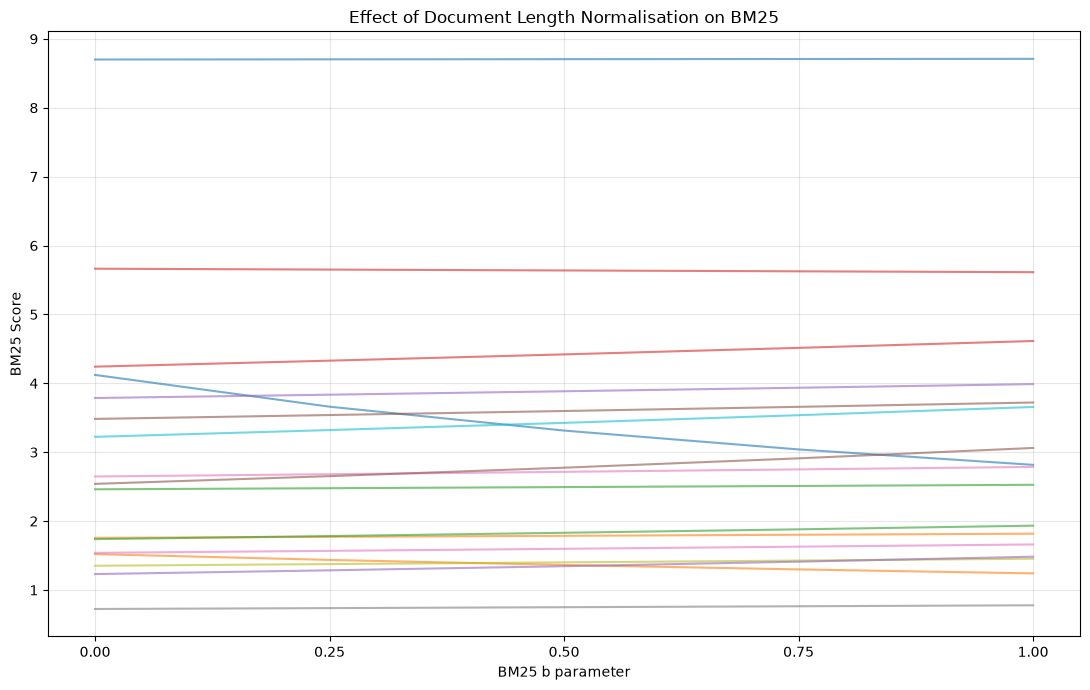

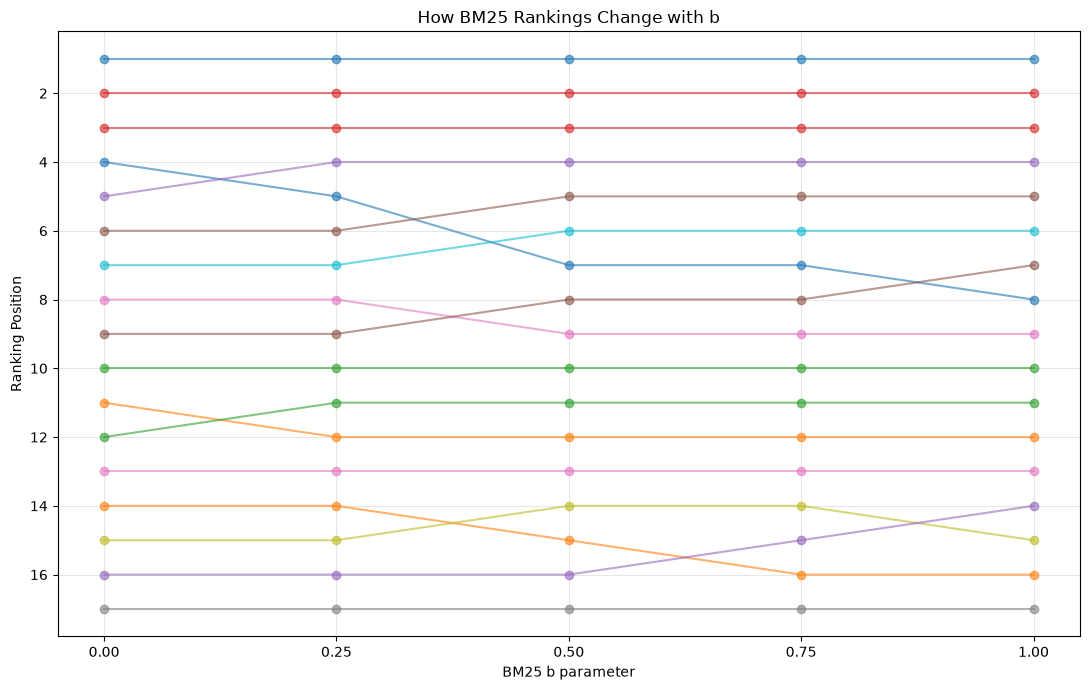

Spearman correlation with baseline (b=0.75):


0.00    0.973039
0.25    0.982843
0.50    0.997549
0.75    1.000000
1.00    0.995098
Name: Correlation, dtype: float64


Top 5 papers at each b value:

b = 0


,title_clean,b=0
10,Evolution and Plasticity of the Transcriptome ...,8.700546
3,Developmental plasticity evolved according to ...,5.663744
13,The Evolution of Phenotypic Plasticity in Resp...,4.241941
0,New Levels of Transcriptome Complexity at Uppe...,4.121943
4,Phenotypic plasticity in response to temperatu...,3.786765



b = 0.25


,title_clean,b=0.25
10,Evolution and Plasticity of the Transcriptome ...,8.702947
3,Developmental plasticity evolved according to ...,5.651061
13,The Evolution of Phenotypic Plasticity in Resp...,4.328946
4,Phenotypic plasticity in response to temperatu...,3.835000
0,New Levels of Transcriptome Complexity at Uppe...,3.660772


... (2 outputs left out)


b = 0.75


,title_clean,b=0.75
10,Evolution and Plasticity of the Transcriptome ...,8.707753
3,Developmental plasticity evolved according to ...,5.625873
13,The Evolution of Phenotypic Plasticity in Resp...,4.514744
4,Phenotypic plasticity in response to temperatu...,3.935826
5,Phenotypic Plasticity of the Drosophila Transc...,3.658596



b = 1.0


,title_clean,b=1.0
10,Evolution and Plasticity of the Transcriptome ...,8.710158
3,Developmental plasticity evolved according to ...,5.613369
13,The Evolution of Phenotypic Plasticity in Resp...,4.614104
4,Phenotypic plasticity in response to temperatu...,3.988569
5,Phenotypic Plasticity of the Drosophila Transc...,3.721543


In [63]:
# ============================================================
# BM25 PARAMETER SENSITIVITY: EFFECT OF b
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi

# Values of b to test
b_values = [0, 0.25, 0.5, 0.75, 1.0]

results = df[["title_clean"]].copy()

# Reuse the tokenized corpus and query from Section 7
for b in b_values:

    bm25_test = BM25Okapi(
        tokenized_corpus,
        k1=1.5,
        b=b
    )

    results[f"b={b}"] = bm25_test.get_scores(
        query_tokens
    )

# ------------------------------------------------------------
# PLOT 1: BM25 SCORE CHANGES
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

for i in range(len(results)):
    plt.plot(
        b_values,
        results.iloc[i, 1:].values.astype(float),
        alpha=0.6
    )

plt.xlabel("BM25 b parameter")
plt.ylabel("BM25 Score")
plt.title("Effect of Document Length Normalisation on BM25")
plt.xticks(b_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# PLOT 2: RANKING CHANGES
# ------------------------------------------------------------

rank_results = results.copy()

for b in b_values:
    rank_results[f"b={b}"] = results[f"b={b}"].rank(
        ascending=False,
        method="min"
    )

plt.figure(figsize=(11, 7))

for i in range(len(rank_results)):
    plt.plot(
        b_values,
        rank_results.iloc[i, 1:].values.astype(float),
        marker="o",
        alpha=0.6
    )

plt.xlabel("BM25 b parameter")
plt.ylabel("Ranking Position")
plt.title("How BM25 Rankings Change with b")
plt.xticks(b_values)
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# RANKING STABILITY
# ------------------------------------------------------------

baseline = rank_results["b=0.75"]

stability = {}

for b in b_values:
    stability[b] = baseline.corr(
        rank_results[f"b={b}"],
        method="spearman"
    )

print("Spearman correlation with baseline (b=0.75):")
display(pd.Series(stability, name="Correlation"))

print("\nTop 5 papers at each b value:")

for b in b_values:
    print(f"\nb = {b}")

    display(
        results.nlargest(
            5, f"b={b}"
        )[["title_clean", f"b={b}"]]
    )

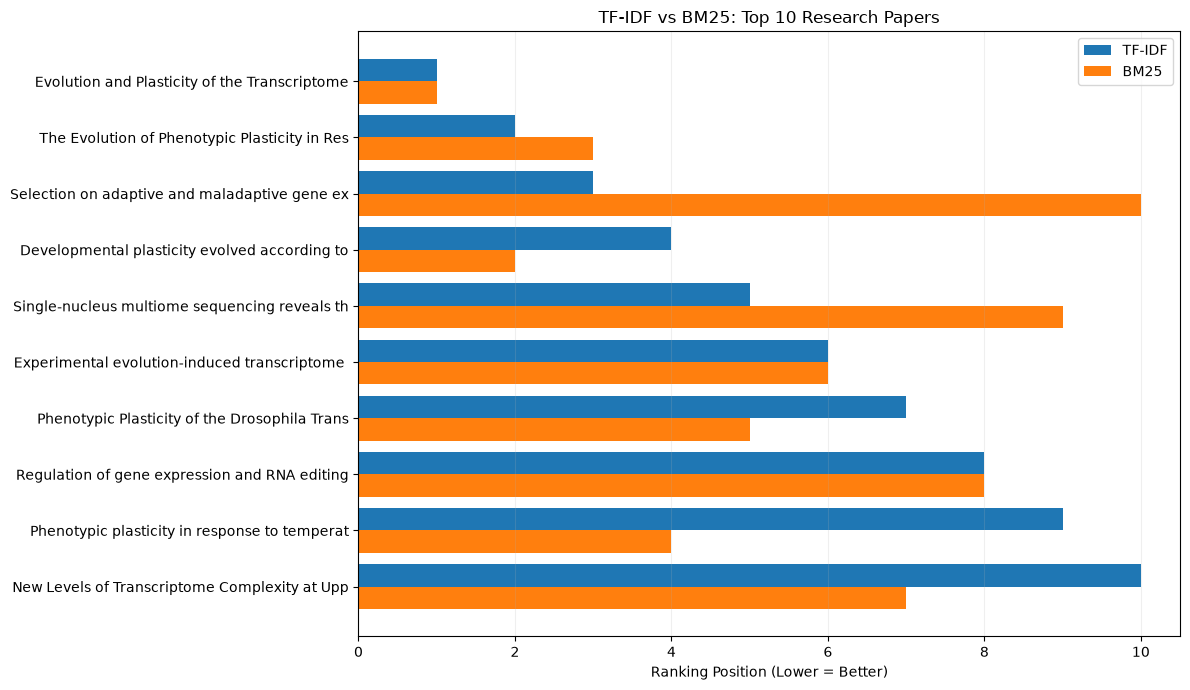

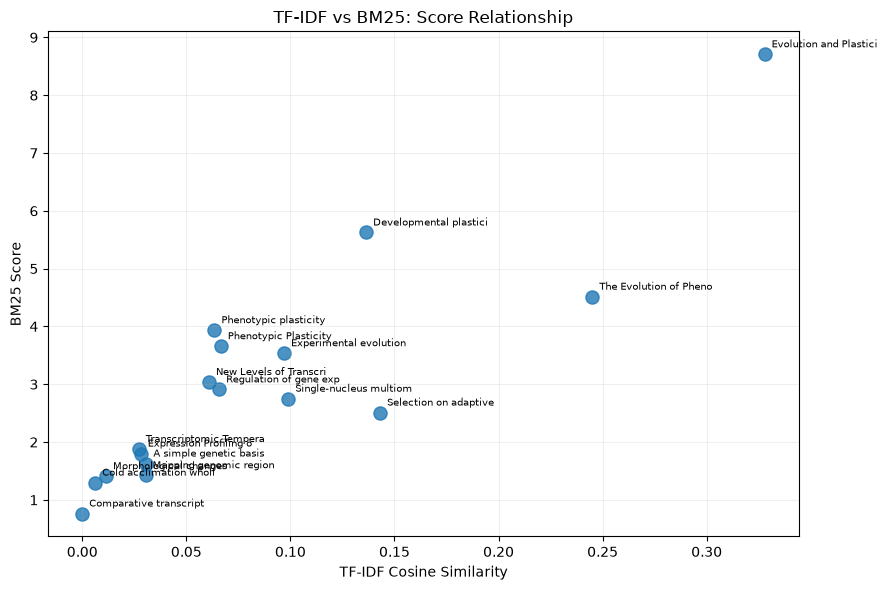

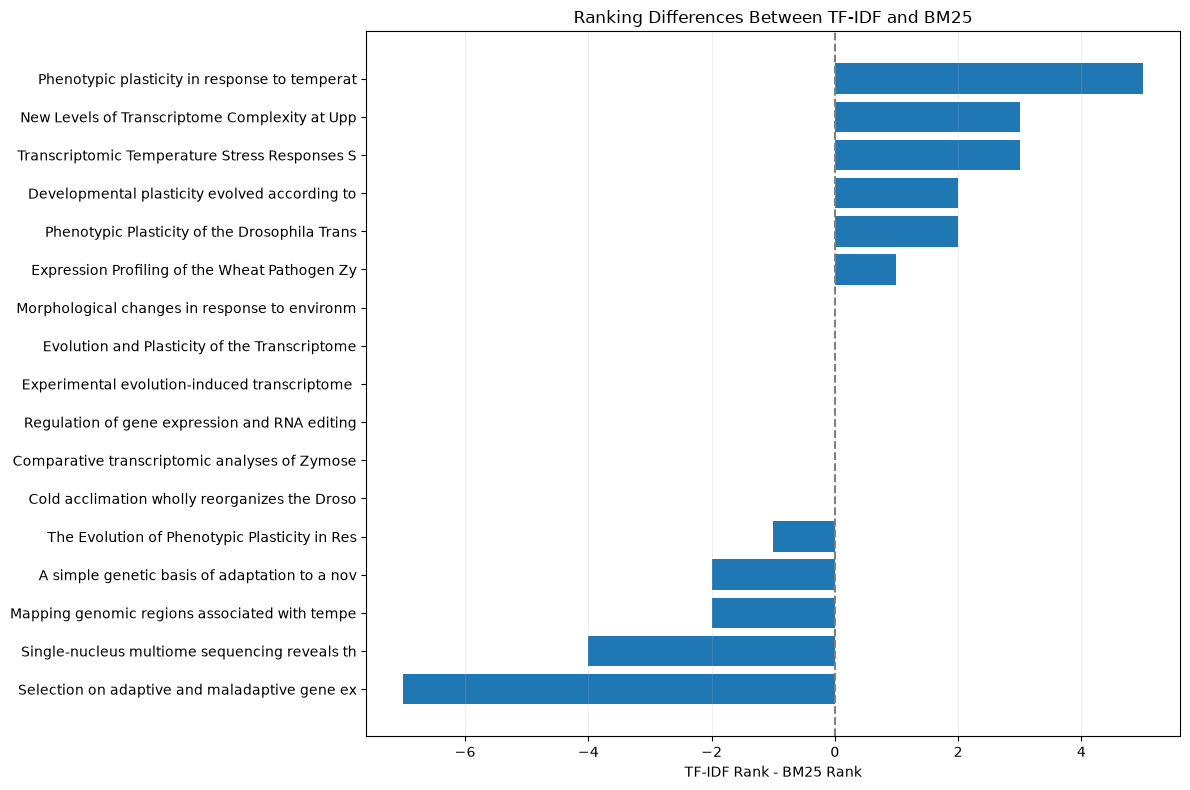

Spearman Rank Correlation: 0.846


,title,tfidf_score,bm25_score,TF-IDF Rank,BM25 Rank,Rank Difference
10,Evolution and Plasticity of the Transcriptome ...,0.327836,8.707753,1,1,0
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097,4.514744,2,3,-1
2,Selection on adaptive and maladaptive gene exp...,0.143097,2.510066,3,10,-7
3,Developmental plasticity evolved according to ...,0.136404,5.625873,4,2,2
6,Single-nucleus multiome sequencing reveals the...,0.099030,2.750376,5,9,-4
9,Experimental evolution-induced transcriptome a...,0.096951,3.537311,6,6,0
5,Phenotypic Plasticity of the Drosophila Transc...,0.066580,3.658596,7,5,2
15,Regulation of gene expression and RNA editing ...,0.065796,2.910909,8,8,0
4,Phenotypic plasticity in response to temperatu...,0.063521,3.935826,9,4,5
0,New Levels of Transcriptome Complexity at Uppe...,0.060903,3.040358,10,7,3


In [54]:
# ============================================================
# RESEARCHMATE: TF-IDF vs BM25 VISUALISATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copy existing results without modifying df
viz_df = df.copy()

# Calculate ranking positions
viz_df["TF-IDF Rank"] = viz_df["tfidf_score"].rank(
    ascending=False, method="min"
).astype(int)

viz_df["BM25 Rank"] = viz_df["bm25_score"].rank(
    ascending=False, method="min"
).astype(int)

# Use existing paper titles
title_col = "title" if "title" in viz_df.columns else "title_clean"

viz_df["Short Title"] = (
    viz_df[title_col]
    .fillna("Untitled")
    .astype(str)
    .str.slice(0, 45)
)

# ============================================================
# PLOT 1: TF-IDF vs BM25 RANKINGS
# ============================================================

plot_df = viz_df.sort_values("TF-IDF Rank").head(10)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    y - 0.2,
    plot_df["TF-IDF Rank"],
    height=0.4,
    label="TF-IDF"
)

ax.barh(
    y + 0.2,
    plot_df["BM25 Rank"],
    height=0.4,
    label="BM25"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Short Title"])
ax.invert_yaxis()

ax.set_xlabel("Ranking Position (Lower = Better)")
ax.set_title("TF-IDF vs BM25: Top 10 Research Papers")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2: TF-IDF SCORE vs BM25 SCORE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    viz_df["tfidf_score"],
    viz_df["bm25_score"],
    s=90,
    alpha=0.8
)

# Annotate points using paper titles
for _, row in viz_df.iterrows():
    ax.annotate(
        row["Short Title"][:22],
        (row["tfidf_score"], row["bm25_score"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7
    )

ax.set_xlabel("TF-IDF Cosine Similarity")
ax.set_ylabel("BM25 Score")
ax.set_title("TF-IDF vs BM25: Score Relationship")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 3: RANKING DIFFERENCES
# ============================================================

viz_df["Rank Difference"] = (
    viz_df["TF-IDF Rank"] - viz_df["BM25 Rank"]
)

rank_df = viz_df.sort_values("Rank Difference")

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    rank_df["Short Title"],
    rank_df["Rank Difference"]
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_xlabel("TF-IDF Rank - BM25 Rank")
ax.set_title("Ranking Differences Between TF-IDF and BM25")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# RANKING CORRELATION AND COMPARISON TABLE
# ============================================================

correlation = viz_df["TF-IDF Rank"].corr(
    viz_df["BM25 Rank"],
    method="spearman"
)

print(f"Spearman Rank Correlation: {correlation:.3f}")

display(
    viz_df[
        [
            title_col,
            "tfidf_score",
            "bm25_score",
            "TF-IDF Rank",
            "BM25 Rank",
            "Rank Difference"
        ]
    ].sort_values("TF-IDF Rank")
)

## 8. Load MiniLM embedding model


In [55]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cpu"
)

print("MiniLM loaded successfully!")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9925.64it/s]


MiniLM loaded successfully!


## 9. Create the query embedding


In [56]:
query_embedding = model.encode(
    [query],
    normalize_embeddings=True
)

print("Query embedding shape:", query_embedding.shape)


Query embedding shape: (1, 384)


## 10. Embedding route 1 — Query vs Keywords


In [57]:
keyword_embeddings = model.encode(
    df["keywords_text"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

df["query_keywords_similarity"] = cosine_similarity(
    query_embedding,
    keyword_embeddings
).flatten()

# For papers with no keywords, similarity is not meaningful
df.loc[
    df["keywords_text"].str.len() == 0,
    "query_keywords_similarity"
] = np.nan

display(
    df.sort_values(
        "query_keywords_similarity",
        ascending=False,
        na_position="last"
    )[
        [
            "title_clean",
            "keywords_clean",
            "query_keywords_similarity"
        ]
    ].head(10)
)


Batches: 100%|██████████| 1/1 [00:00<00:00, 19.76it/s]


,title_clean,keywords_clean,query_keywords_similarity
10,Evolution and Plasticity of the Transcriptome ...,RNA-seq adaptive evolution experimental evolut...,0.796122
13,The Evolution of Phenotypic Plasticity in Resp...,Drosophila experimental evolution gene express...,0.778096
3,Developmental plasticity evolved according to ...,Drosophila experimental evolution performance ...,0.647887
4,Phenotypic plasticity in response to temperatu...,Adaptation climatic variability genotype heat ...,0.605338
9,Experimental evolution-induced transcriptome a...,Genomic adaptation Physiological assays Therma...,0.589518
6,Single-nucleus multiome sequencing reveals the...,Embryogenesis Gene regulatory networks Plasticity,0.588197
0,New Levels of Transcriptome Complexity at Uppe...,Drosophila heat stress splicing thermal extrem...,0.581030
16,A simple genetic basis of adaptation to a nove...,Evolve and resequence Experimental evolution P...,0.534144
12,Transcriptomic Temperature Stress Responses Sh...,climate change vulnerability comparative trans...,0.460999
8,Mapping genomic regions associated with temper...,Mycosphaerella graminicola QTL fungi heat stre...,0.259017


## 11. Embedding route 2 — Query vs Title + Abstract


In [58]:
title_abstract_embeddings = model.encode(
    df["title_abstract_text"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

df["query_title_abstract_similarity"] = cosine_similarity(
    query_embedding,
    title_abstract_embeddings
).flatten()

display(
    df.sort_values(
        "query_title_abstract_similarity",
        ascending=False
    )[
        [
            "title_clean",
            "query_title_abstract_similarity"
        ]
    ].head(10)
)


Batches: 100%|██████████| 1/1 [00:00<00:00,  3.21it/s]


,title_clean,query_title_abstract_similarity
13,The Evolution of Phenotypic Plasticity in Resp...,0.777024
3,Developmental plasticity evolved according to ...,0.647274
9,Experimental evolution-induced transcriptome a...,0.633362
10,Evolution and Plasticity of the Transcriptome ...,0.620657
4,Phenotypic plasticity in response to temperatu...,0.612141
0,New Levels of Transcriptome Complexity at Uppe...,0.583251
2,Selection on adaptive and maladaptive gene exp...,0.577115
6,Single-nucleus multiome sequencing reveals the...,0.551162
12,Transcriptomic Temperature Stress Responses Sh...,0.530965
16,A simple genetic basis of adaptation to a nove...,0.525122


## 12. Compare the two semantic rankings


In [59]:
comparison = df[
    [
        "doi",
        "title_clean",
        "keywords_clean",
        "query_keywords_similarity",
        "query_title_abstract_similarity"
    ]
].copy()

comparison["keywords_rank"] = (
    comparison["query_keywords_similarity"]
    .rank(method="min", ascending=False)
)

comparison["title_abstract_rank"] = (
    comparison["query_title_abstract_similarity"]
    .rank(method="min", ascending=False)
)

display(
    comparison.sort_values(
        "title_abstract_rank",
        ascending=True
    )
)


,doi,title_clean,keywords_clean,query_keywords_similarity,query_title_abstract_similarity,keywords_rank,title_abstract_rank
13,10.1093/gbe/evaa206,The Evolution of Phenotypic Plasticity in Resp...,Drosophila experimental evolution gene express...,0.778096,0.777024,2.0,1.0
3,10.1098/rsbl.2016.0379,Developmental plasticity evolved according to ...,Drosophila experimental evolution performance ...,0.647887,0.647274,3.0,2.0
9,10.1242/jeb.251365,Experimental evolution-induced transcriptome a...,Genomic adaptation Physiological assays Therma...,0.589518,0.633362,5.0,3.0
10,10.3389/fmicb.2020.573829,Evolution and Plasticity of the Transcriptome ...,RNA-seq adaptive evolution experimental evolut...,0.796122,0.620657,1.0,4.0
4,10.1093/aobpla/ply043,Phenotypic plasticity in response to temperatu...,Adaptation climatic variability genotype heat ...,0.605338,0.612141,4.0,5.0
0,10.1534/genetics.113.156224,New Levels of Transcriptome Complexity at Uppe...,Drosophila heat stress splicing thermal extrem...,0.581030,0.583251,7.0,6.0
2,10.1038/s41467-021-26334-4,Selection on adaptive and maladaptive gene exp...,,NaN,0.577115,NaN,7.0
6,10.1242/dev.205729,Single-nucleus multiome sequencing reveals the...,Embryogenesis Gene regulatory networks Plasticity,0.588197,0.551162,6.0,8.0
12,10.1093/gbe/evaf056,Transcriptomic Temperature Stress Responses Sh...,climate change vulnerability comparative trans...,0.460999,0.530965,9.0,9.0
16,10.1186/s13059-018-1503-4,A simple genetic basis of adaptation to a nove...,Evolve and resequence Experimental evolution P...,0.534144,0.525122,8.0,10.0


,title_clean,TF-IDF Rank,BM25 Rank,MiniLM (Title + Abstract) Rank,MiniLM (Keywords) Rank
10,Evolution and Plasticity of the Transcriptome ...,1.0,1.0,4.0,1.0
13,The Evolution of Phenotypic Plasticity in Resp...,2.0,3.0,1.0,2.0
2,Selection on adaptive and maladaptive gene exp...,3.0,10.0,7.0,NaN
3,Developmental plasticity evolved according to ...,4.0,2.0,2.0,3.0
6,Single-nucleus multiome sequencing reveals the...,5.0,9.0,8.0,6.0
9,Experimental evolution-induced transcriptome a...,6.0,6.0,3.0,5.0
5,Phenotypic Plasticity of the Drosophila Transc...,7.0,5.0,11.0,NaN
15,Regulation of gene expression and RNA editing ...,8.0,8.0,14.0,NaN
4,Phenotypic plasticity in response to temperatu...,9.0,4.0,5.0,4.0
0,New Levels of Transcriptome Complexity at Uppe...,10.0,7.0,6.0,7.0


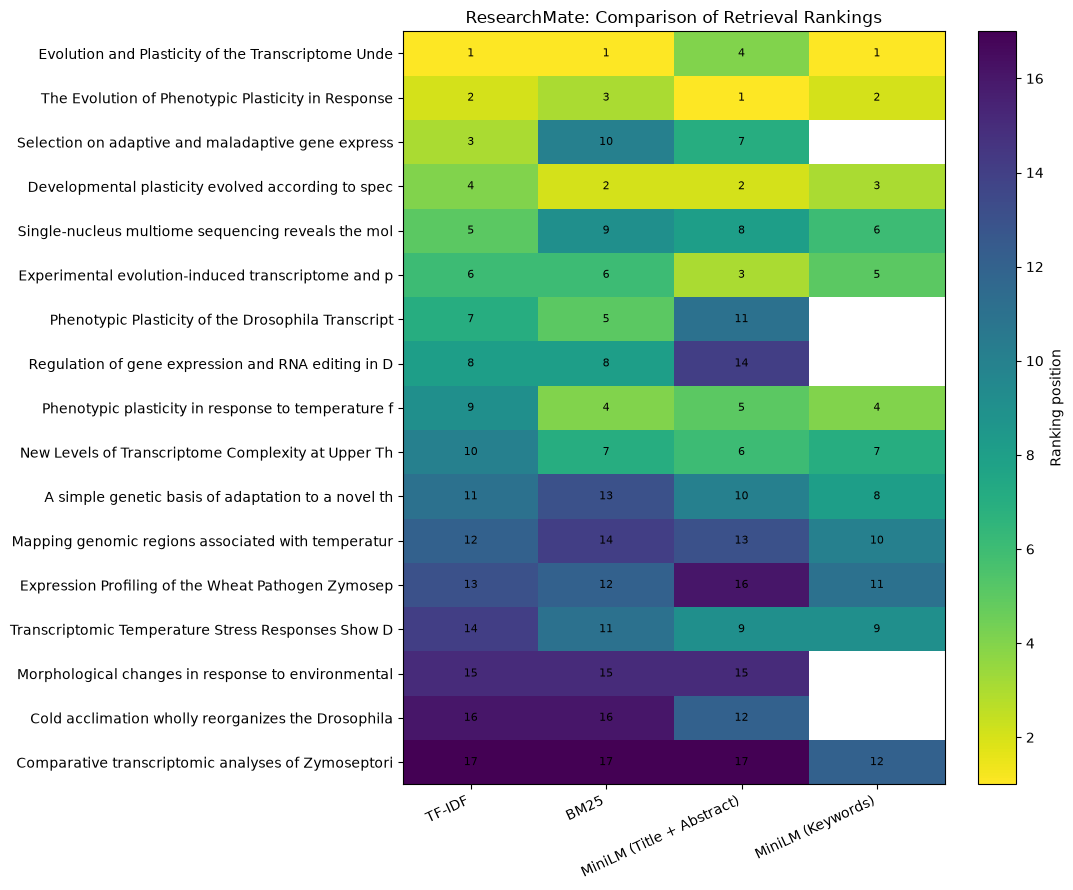

Spearman Rank Correlation:


,TF-IDF Rank,BM25 Rank,MiniLM (Title + Abstract) Rank,MiniLM (Keywords) Rank
TF-IDF Rank,1.000,0.846,0.775,0.951
BM25 Rank,0.846,1.000,0.814,0.951
MiniLM (Title + Abstract) Rank,0.775,0.814,1.000,0.930
MiniLM (Keywords) Rank,0.951,0.951,0.930,1.000



TOP 5: TF-IDF


,title_clean,tfidf_score
10,Evolution and Plasticity of the Transcriptome ...,0.327836
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097
2,Selection on adaptive and maladaptive gene exp...,0.143097
3,Developmental plasticity evolved according to ...,0.136404
6,Single-nucleus multiome sequencing reveals the...,0.099030



TOP 5: BM25


,title_clean,bm25_score
10,Evolution and Plasticity of the Transcriptome ...,8.707753
3,Developmental plasticity evolved according to ...,5.625873
13,The Evolution of Phenotypic Plasticity in Resp...,4.514744
4,Phenotypic plasticity in response to temperatu...,3.935826
5,Phenotypic Plasticity of the Drosophila Transc...,3.658596



TOP 5: MiniLM (Title + Abstract)


,title_clean,query_title_abstract_similarity
13,The Evolution of Phenotypic Plasticity in Resp...,0.777024
3,Developmental plasticity evolved according to ...,0.647274
9,Experimental evolution-induced transcriptome a...,0.633362
10,Evolution and Plasticity of the Transcriptome ...,0.620657
4,Phenotypic plasticity in response to temperatu...,0.612141



TOP 5: MiniLM (Keywords)


,title_clean,query_keywords_similarity
10,Evolution and Plasticity of the Transcriptome ...,0.796122
13,The Evolution of Phenotypic Plasticity in Resp...,0.778096
3,Developmental plasticity evolved according to ...,0.647887
4,Phenotypic plasticity in response to temperatu...,0.605338
9,Experimental evolution-induced transcriptome a...,0.589518


In [64]:
# ============================================================
# RESEARCHMATE: COMPARE TF-IDF, BM25 AND MINILM
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use existing scores from the notebook
score_columns = {
    "TF-IDF": "tfidf_score",
    "BM25": "bm25_score",
    "MiniLM (Title + Abstract)": "query_title_abstract_similarity",
    "MiniLM (Keywords)": "query_keywords_similarity"
}

comparison = df[["title_clean"] + list(score_columns.values())].copy()

# Calculate ranks separately for each method
for method, column in score_columns.items():
    comparison[method + " Rank"] = comparison[column].rank(
        ascending=False,
        method="min"
    )

# ------------------------------------------------------------
# 1. COMPARISON TABLE
# ------------------------------------------------------------

rank_columns = [method + " Rank" for method in score_columns]

display(
    comparison[
        ["title_clean"] + rank_columns
    ].sort_values("TF-IDF Rank")
)

# ------------------------------------------------------------
# 2. RANKING HEATMAP
# ------------------------------------------------------------

plot_df = comparison.sort_values("TF-IDF Rank")

rank_matrix = plot_df[rank_columns].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(rank_matrix, aspect="auto", cmap="viridis_r")

ax.set_xticks(range(len(rank_columns)))
ax.set_xticklabels(
    list(score_columns.keys()),
    rotation=25,
    ha="right"
)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(
    plot_df["title_clean"].str.slice(0, 50)
)

for i in range(len(plot_df)):
    for j in range(len(rank_columns)):
        value = rank_matrix[i, j]
        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.0f}",
                ha="center", va="center", fontsize=8
            )

plt.colorbar(im, ax=ax, label="Ranking position")
ax.set_title("ResearchMate: Comparison of Retrieval Rankings")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. RANK CORRELATION
# ------------------------------------------------------------

rank_correlation = comparison[rank_columns].corr(
    method="spearman"
)

print("Spearman Rank Correlation:")
display(rank_correlation.round(3))

# ------------------------------------------------------------
# 4. TOP 5 PAPERS BY METHOD
# ------------------------------------------------------------

for method, column in score_columns.items():

    print(f"\nTOP 5: {method}")

    display(
        comparison[
            ["title_clean", column]
        ].sort_values(
            column, ascending=False,
            na_position="last"
        ).head(5)
    )

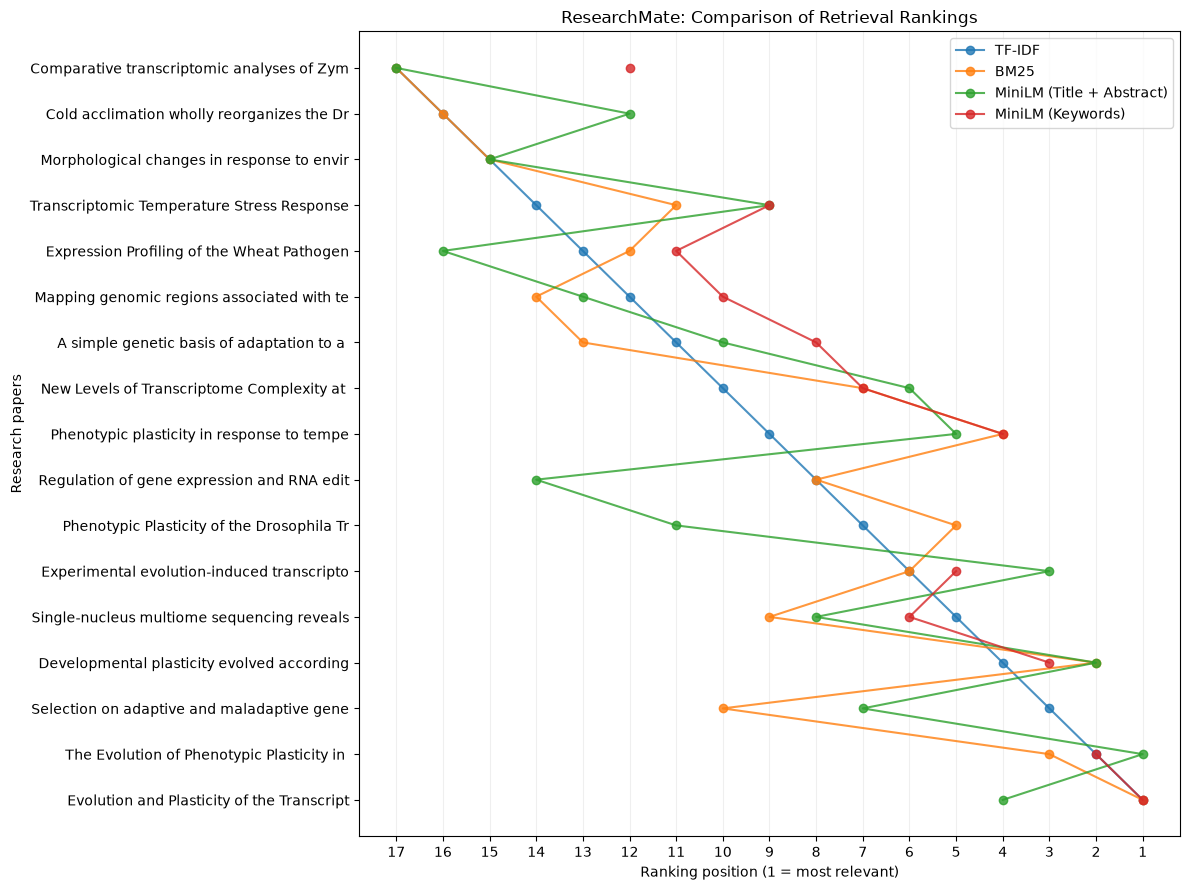

In [65]:
# ============================================================
# TF-IDF vs BM25 vs MiniLM: Ranking Comparison
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Existing scores
methods = {
    "TF-IDF": "tfidf_score",
    "BM25": "bm25_score",
    "MiniLM (Title + Abstract)": "query_title_abstract_similarity",
    "MiniLM (Keywords)": "query_keywords_similarity"
}

plot_df = df.copy()

# Calculate ranks
for method, column in methods.items():
    plot_df[method] = plot_df[column].rank(
        ascending=False,
        method="min"
    )

# Sort papers according to TF-IDF rank
plot_df = plot_df.sort_values("TF-IDF")

# Shorten titles
plot_df["short_title"] = (
    plot_df["title_clean"]
    .astype(str)
    .str.slice(0, 42)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 9))

for method in methods:
    ax.plot(
        plot_df[method],
        plot_df["short_title"],
        marker="o",
        linestyle="-",
        label=method,
        alpha=0.8
    )

ax.set_xlabel("Ranking position (1 = most relevant)")
ax.set_ylabel("Research papers")
ax.set_title("ResearchMate: Comparison of Retrieval Rankings")

ax.set_xticks(range(1, len(plot_df) + 1))
ax.invert_xaxis()
ax.grid(axis="x", alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# WEIGHTED SEMANTIC SIMILARITY: 75% TITLE+ABSTRACT, 25% KEYWORDS
# ============================================================

import pandas as pd
import numpy as np

# Ensure similarity columns are numeric
ta = pd.to_numeric(
    df["query_title_abstract_similarity"],
    errors="coerce"
)

kw = pd.to_numeric(
    df["query_keywords_similarity"],
    errors="coerce"
)

# Check missing values
print("Missing title+abstract scores:", ta.isna().sum())
print("Missing keyword scores:", kw.isna().sum())

# Calculate weighted similarity
# Missing keywords -> use title+abstract score only
df["weighted_similarity_75_25"] = np.where(
    kw.notna(),
    0.75 * ta + 0.25 * kw,
    ta
)

# Rank papers, allowing missing scores
df["weighted_rank_75_25"] = (
    df["weighted_similarity_75_25"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

# Display results
display(
    df[
        [
            "title_clean",
            "query_title_abstract_similarity",
            "query_keywords_similarity",
            "weighted_similarity_75_25",
            "weighted_rank_75_25"
        ]
    ].sort_values("weighted_rank_75_25")
)

Missing title+abstract scores: 0
Missing keyword scores: 5


,title_clean,query_title_abstract_similarity,query_keywords_similarity,weighted_similarity_75_25,weighted_rank_75_25
13,The Evolution of Phenotypic Plasticity in Resp...,0.777024,0.778096,0.777292,1
10,Evolution and Plasticity of the Transcriptome ...,0.620657,0.796122,0.664524,2
3,Developmental plasticity evolved according to ...,0.647274,0.647887,0.647427,3
9,Experimental evolution-induced transcriptome a...,0.633362,0.589518,0.622401,4
4,Phenotypic plasticity in response to temperatu...,0.612141,0.605338,0.610441,5
0,New Levels of Transcriptome Complexity at Uppe...,0.583251,0.581030,0.582696,6
2,Selection on adaptive and maladaptive gene exp...,0.577115,NaN,0.577115,7
6,Single-nucleus multiome sequencing reveals the...,0.551162,0.588197,0.560421,8
16,A simple genetic basis of adaptation to a nove...,0.525122,0.534144,0.527377,9
5,Phenotypic Plasticity of the Drosophila Transc...,0.519388,NaN,0.519388,10


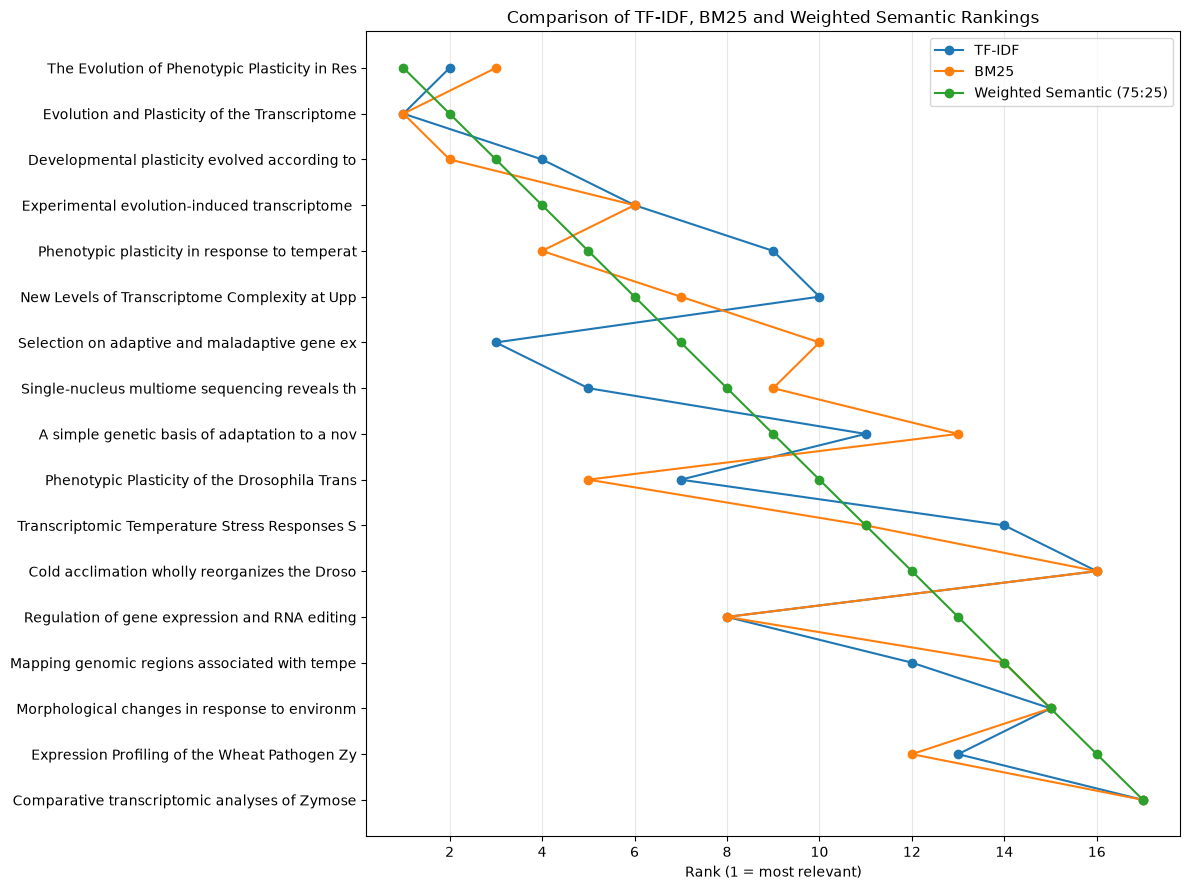

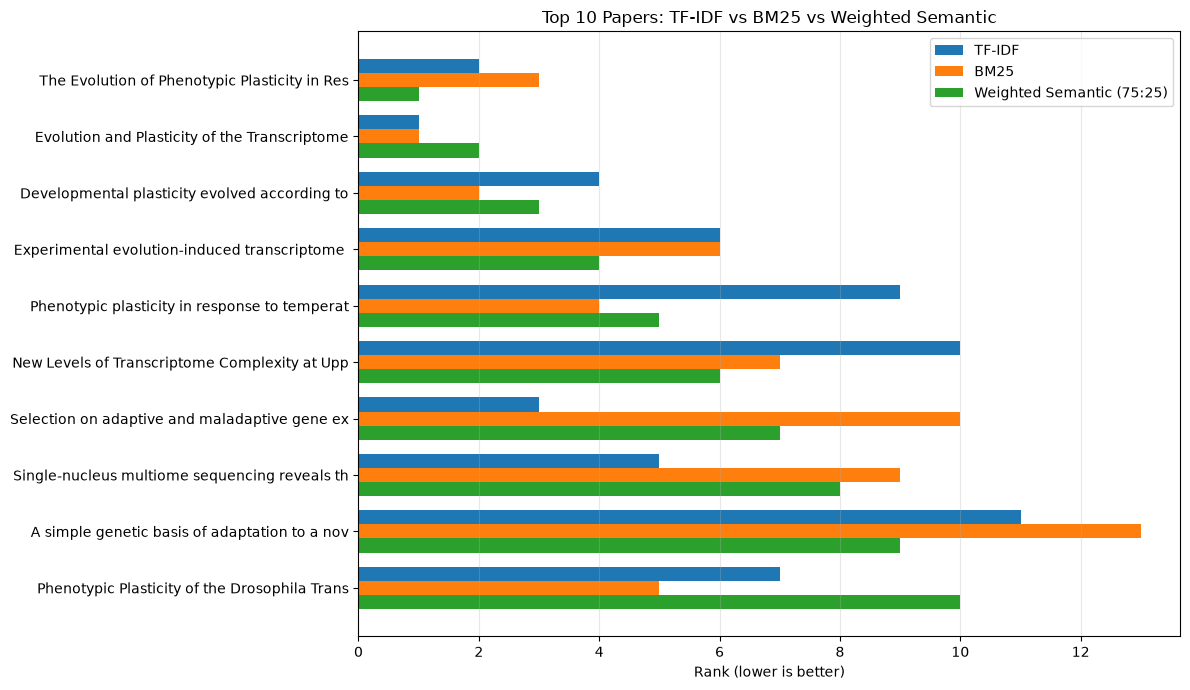

,title_clean,tfidf_score,bm25_score,weighted_similarity_75_25,TF-IDF Rank,BM25 Rank,weighted_rank_75_25
13,The Evolution of Phenotypic Plasticity in Resp...,0.245097,4.514744,0.777292,2,3,1
10,Evolution and Plasticity of the Transcriptome ...,0.327836,8.707753,0.664524,1,1,2
3,Developmental plasticity evolved according to ...,0.136404,5.625873,0.647427,4,2,3
9,Experimental evolution-induced transcriptome a...,0.096951,3.537311,0.622401,6,6,4
4,Phenotypic plasticity in response to temperatu...,0.063521,3.935826,0.610441,9,4,5
0,New Levels of Transcriptome Complexity at Uppe...,0.060903,3.040358,0.582696,10,7,6
2,Selection on adaptive and maladaptive gene exp...,0.143097,2.510066,0.577115,3,10,7
6,Single-nucleus multiome sequencing reveals the...,0.099030,2.750376,0.560421,5,9,8
16,A simple genetic basis of adaptation to a nove...,0.030829,1.628860,0.527377,11,13,9
5,Phenotypic Plasticity of the Drosophila Transc...,0.066580,3.658596,0.519388,7,5,10


In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------

plot_df = df.copy()

# Decide which title column exists
title_col = "title_clean" if "title_clean" in plot_df.columns else "title"

# Calculate TF-IDF and BM25 ranks
plot_df["TF-IDF Rank"] = (
    plot_df["tfidf_score"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

plot_df["BM25 Rank"] = (
    plot_df["bm25_score"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

# Use the weighted rank you already created
# If it doesn't exist for some reason, create it
if "weighted_rank_75_25" not in plot_df.columns:
    plot_df["weighted_rank_75_25"] = (
        plot_df["weighted_similarity_75_25"]
        .rank(ascending=False, method="min")
        .astype("Int64")
    )

# Short titles for plotting
plot_df["Short Title"] = (
    plot_df[title_col]
    .fillna("Untitled")
    .astype(str)
    .str.slice(0, 45)
)

# Sort by weighted rank for easier interpretation
plot_df = plot_df.sort_values("weighted_rank_75_25")

# ------------------------------------------------------------
# PLOT 1: RANK COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9))

y = np.arange(len(plot_df))

ax.plot(plot_df["TF-IDF Rank"], y, marker="o", label="TF-IDF")
ax.plot(plot_df["BM25 Rank"], y, marker="o", label="BM25")
ax.plot(plot_df["weighted_rank_75_25"], y, marker="o", label="Weighted Semantic (75:25)")

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Short Title"])
ax.invert_yaxis()

ax.set_xlabel("Rank (1 = most relevant)")
ax.set_title("Comparison of TF-IDF, BM25 and Weighted Semantic Rankings")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PLOT 2: TOP 10 BAR CHART COMPARISON
# ------------------------------------------------------------

top10 = plot_df.head(10).copy()
y = np.arange(len(top10))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(y - bar_width, top10["TF-IDF Rank"], height=bar_width, label="TF-IDF")
ax.barh(y, top10["BM25 Rank"], height=bar_width, label="BM25")
ax.barh(y + bar_width, top10["weighted_rank_75_25"], height=bar_width, label="Weighted Semantic (75:25)")

ax.set_yticks(y)
ax.set_yticklabels(top10["Short Title"])
ax.invert_yaxis()

ax.set_xlabel("Rank (lower is better)")
ax.set_title("Top 10 Papers: TF-IDF vs BM25 vs Weighted Semantic")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# OPTIONAL: VIEW TABLE
# ------------------------------------------------------------

display(
    plot_df[
        [
            title_col,
            "tfidf_score",
            "bm25_score",
            "weighted_similarity_75_25",
            "TF-IDF Rank",
            "BM25 Rank",
            "weighted_rank_75_25",
        ]
    ]
)

## 13. Optional combined semantic score

Use this only after first looking at the two representations separately.

If a paper has no keywords, this version falls back to the title+abstract score.


In [60]:
df["combined_embedding_score"] = np.where(
    df["query_keywords_similarity"].notna(),
    0.5 * df["query_keywords_similarity"] +
    0.5 * df["query_title_abstract_similarity"],
    df["query_title_abstract_similarity"]
)

display(
    df.sort_values(
        "combined_embedding_score",
        ascending=False
    )[
        [
            "title_clean",
            "query_keywords_similarity",
            "query_title_abstract_similarity",
            "combined_embedding_score"
        ]
    ].head(10)
)


,title_clean,query_keywords_similarity,query_title_abstract_similarity,combined_embedding_score
13,The Evolution of Phenotypic Plasticity in Resp...,0.778096,0.777024,0.777560
10,Evolution and Plasticity of the Transcriptome ...,0.796122,0.620657,0.708390
3,Developmental plasticity evolved according to ...,0.647887,0.647274,0.647580
9,Experimental evolution-induced transcriptome a...,0.589518,0.633362,0.611440
4,Phenotypic plasticity in response to temperatu...,0.605338,0.612141,0.608740
0,New Levels of Transcriptome Complexity at Uppe...,0.581030,0.583251,0.582140
2,Selection on adaptive and maladaptive gene exp...,NaN,0.577115,0.577115
6,Single-nucleus multiome sequencing reveals the...,0.588197,0.551162,0.569679
16,A simple genetic basis of adaptation to a nove...,0.534144,0.525122,0.529633
5,Phenotypic Plasticity of the Drosophila Transc...,NaN,0.519388,0.519388


## 14. Save results


In [61]:
output_columns = [
    "doi",
    "title",
    "author",
    "keywords",
    "year",
    "tfidf_score",
    "bm25_score",
    "query_keywords_similarity",
    "query_title_abstract_similarity",
    "combined_embedding_score"
]

df[output_columns].to_csv(
    "retrieval_embedding_results.csv",
    index=False
)

print("Saved retrieval_embedding_results.csv")


Saved retrieval_embedding_results.csv


## 15. Save embeddings for reuse


In [62]:
np.save("query_embedding.npy", query_embedding)
np.save("keyword_embeddings.npy", keyword_embeddings)
np.save("title_abstract_embeddings.npy", title_abstract_embeddings)

print("Saved:")
print("- query_embedding.npy")
print("- keyword_embeddings.npy")
print("- title_abstract_embeddings.npy")


Saved:
- query_embedding.npy
- keyword_embeddings.npy
- title_abstract_embeddings.npy


## Key point about cleaning

For **MiniLM / transformer embeddings**, avoid aggressive preprocessing.

Good:
- normalize whitespace
- remove accidental line breaks
- convert keyword separators such as `;` into spaces

Usually unnecessary:
- stemming
- lemmatization
- removing all punctuation
- removing stopwords
- lowercasing everything manually

The model was trained on natural language, so keeping title and abstract close to their original wording is usually better.
